# EDA Credit Risk Dataset

Целью работы является проведение разведочного анализа данных кредитного датасета, оценка его структуры, распределения признаков, наличие пропусков, аномалий и выбросов.

## 1. Загрузка данных

In [19]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
current = Path.cwd()

project_root = next(
    parent
    for parent in [current, *current.parents]
    if (parent / "pyproject.toml").exists()
)

data_path = project_root / "data" / "credit.parquet"

df = pd.read_parquet(data_path)

## 2. Общая структура датасета

Оцениваем данные и их размеры

In [21]:
df

,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,job,dependents,telephone,foreign_worker,default
0,< 0 DM,6,critical,radio/tv,1169,unknown,> 7 yrs,4,single male,none,...,real estate,67,none,own,2,skilled employee,1,yes,yes,1
1,1 - 200 DM,48,repaid,radio/tv,5951,< 100 DM,1 - 4 yrs,2,female,none,...,real estate,22,none,own,1,skilled employee,1,none,yes,2
2,unknown,12,critical,education,2096,< 100 DM,4 - 7 yrs,2,single male,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,1
3,< 0 DM,42,repaid,furniture,7882,< 100 DM,4 - 7 yrs,2,single male,guarantor,...,building society savings,45,none,for free,1,skilled employee,2,none,yes,1
4,< 0 DM,24,delayed,car (new),4870,< 100 DM,1 - 4 yrs,3,single male,none,...,unknown/none,53,none,for free,2,skilled employee,2,none,yes,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,unknown,12,repaid,furniture,1736,< 100 DM,4 - 7 yrs,3,female,none,...,real estate,31,none,own,1,unskilled resident,1,none,yes,1
996,< 0 DM,30,repaid,car (used),3857,< 100 DM,1 - 4 yrs,4,divorced male,none,...,building society savings,40,none,own,1,mangement self-employed,1,yes,yes,1
997,unknown,12,repaid,radio/tv,804,< 100 DM,> 7 yrs,4,single male,none,...,other,38,none,own,1,skilled employee,1,none,yes,1
998,< 0 DM,45,repaid,radio/tv,1845,< 100 DM,1 - 4 yrs,4,single male,none,...,unknown/none,23,none,for free,1,skilled employee,1,yes,yes,2


Размер датасета

In [22]:
df.shape

(1000, 21)

Датасет содержит 1000 наблюдений и 21 столбец: 20 признаков и 1 целевую переменную `default`.

### Типы данных

Проверим типы признаков в датасете.

In [23]:
df.dtypes

checking_balance        string
months_loan_duration     Int64
credit_history          string
purpose                 string
amount                   Int64
savings_balance         string
employment_length       string
installment_rate         Int64
personal_status         string
other_debtors           string
residence_history        Int64
property                string
age                      Int64
installment_plan        string
housing                 string
existing_credits         Int64
job                     string
dependents               Int64
telephone               string
foreign_worker          string
default                  Int64
dtype: object

В датасете присутствуют числовые и категориальные признаки. Целевая переменная `default` представлена числовым типом.

## 3. Описательная статистика

### Числовые признаки

Рассмотрим основные статистики числовых признаков.

In [24]:
df.describe()

,months_loan_duration,amount,installment_rate,residence_history,age,existing_credits,dependents,default
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.903,3271.258,2.973,2.845,35.546,1.407,1.155,1.3
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0,1.0
75%,24.0,3972.25,4.0,4.0,42.0,2.0,1.0,2.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0,2.0


- months_loan_duration - Срок кредита в месяцах
- amount - Сумма кредита (в немецких марках), возможно присутствует выброс: при среднем 3271 видим максимальное 18424, хотя 75 процентиль на 3972
- installment_rate - Сумма выплат в процентах от дохода
- residence_history - Годы проживания по текущему адресу
- age - возраст
- existing_credits - Количество существующих кредитов
- dependents - Количество иждивенцев

### Категориальные признаки

Рассмотрим основные характеристики категориальных признаков.

In [25]:
df.describe(include=["object", "string"])

,checking_balance,credit_history,purpose,savings_balance,employment_length,personal_status,other_debtors,property,installment_plan,housing,job,telephone,foreign_worker
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,4,5,10,5,5,4,3,4,3,3,4,2,2
top,unknown,repaid,radio/tv,< 100 DM,1 - 4 yrs,single male,none,other,none,own,skilled employee,none,yes
freq,394,530,280,603,339,548,907,332,814,713,630,596,963


- checking_balance - баланс расчётного счёта, присутствует много неизвестных значений: **unknown**
- credit_history - кредитная история
- purpose - цель кредита
- savings_balance - баланс сберегательного счёта
- employment_length - стаж работы
- personal_status - семейное положение и пол
- other_debtors - поручители, много пропусков **none**
- property - имущество, много объектов категории **other**
- installment_plan - другие планы рассрочки, много **none**
- housing - жилищный статус
- job - категория занятости / профессии
- telephone - наличие зарегистрированного телефона, много пропусков **none**
- foreign_worker - признак иностранного работника

## 4. Пропуски и аномальные значения

Сначала проверим наличие стандартных пропущенных значений `NaN`.

In [26]:
df.isna().sum()

checking_balance        0
months_loan_duration    0
credit_history          0
purpose                 0
amount                  0
savings_balance         0
employment_length       0
installment_rate        0
personal_status         0
other_debtors           0
residence_history       0
property                0
age                     0
installment_plan        0
housing                 0
existing_credits        0
job                     0
dependents              0
telephone               0
foreign_worker          0
default                 0
dtype: int64

Так как датасет предобработан, то стандартных пропусков "Nan" тут нет.

В категориальных признаках отсутствующие или специальные значения могут быть представлены строкой `none`. Оценим их расположение в датасете.

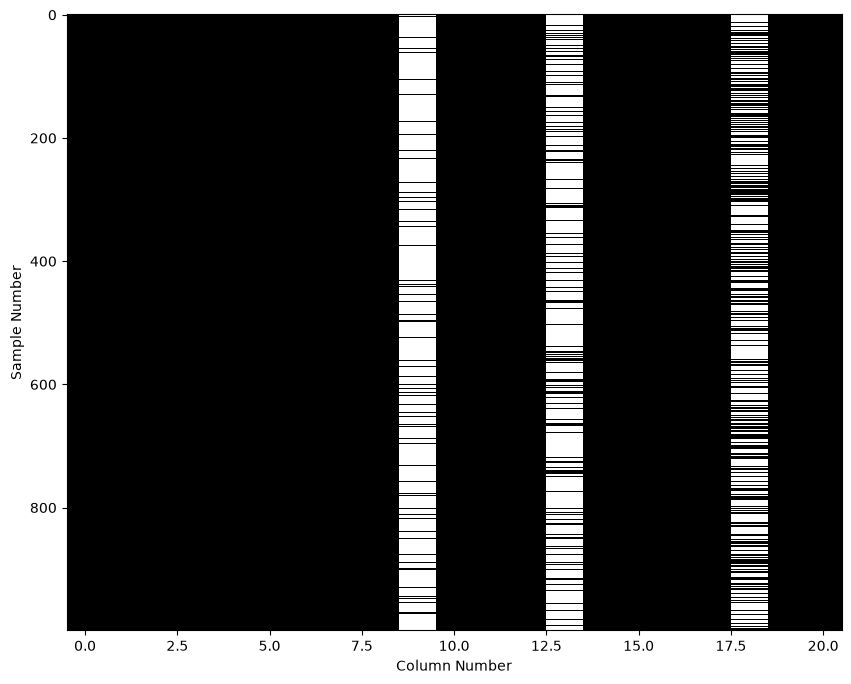

In [27]:
mask = df.astype("string").apply(
    lambda col: col.str.strip().str.lower().eq("none")
)

plt.figure(figsize=(10, 8))
plt.imshow(
    mask.to_numpy(dtype=bool, na_value=False),
    aspect="auto",
    interpolation="nearest",
    cmap="gray"
)
plt.xlabel("Column Number")
plt.ylabel("Sample Number")
plt.show()

Так как датасет был изначально обработан, то пропуски здесь хранятся как значения "none"

In [28]:
(df == "none").sum()

checking_balance          0
months_loan_duration      0
credit_history            0
purpose                   0
amount                    0
savings_balance           0
employment_length         0
installment_rate          0
personal_status           0
other_debtors           907
residence_history         0
property                  0
age                       0
installment_plan        814
housing                   0
existing_credits          0
job                       0
dependents                0
telephone               596
foreign_worker            0
default                   0
dtype: object

Также проверим количество значений `unknown`

In [29]:
(df == "unknown").sum()

checking_balance        394
months_loan_duration      0
credit_history            0
purpose                   0
amount                    0
savings_balance         183
employment_length         0
installment_rate          0
personal_status           0
other_debtors             0
residence_history         0
property                  0
age                       0
installment_plan          0
housing                   0
existing_credits          0
job                       0
dependents                0
telephone                 0
foreign_worker            0
default                   0
dtype: object

Значения `none` встречаются в нескольких категориальных признаках. При этом их не всегда следует считать обычными пропусками: например, `none` может означать отсутствие поручителя или дополнительного плана рассрочки.

Значения `unknown` также требуют отдельного внимания при дальнейшей подготовке данных.

## 5. Распределения признаков

### Числовые признаки

Рассмотрим распределения числовых признаков.

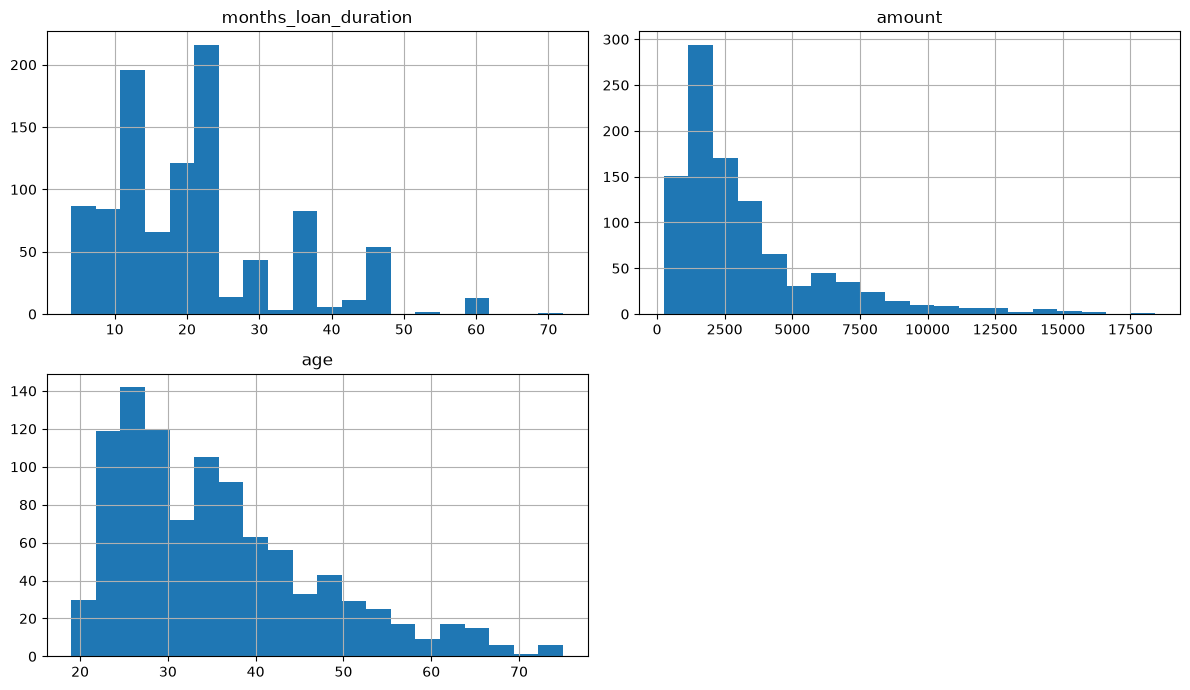

In [30]:
numeric_columns = [
    "months_loan_duration",
    "amount",
    "age"
]

df[numeric_columns].hist(
    figsize=(12, 7),
    bins=20
)

plt.tight_layout()
plt.show()

По распределениям видно:

- `amount` имеет выраженную правостороннюю асимметрию: большинство кредитов имеют небольшую сумму, но есть и редкие большие суммы
- `age` также имеет правостороннюю асимметрию: большее число клиентов являются молодыми
- `months_loan_duration` наиболее часто встречаются стандартные сроки кредитования.

### Дискретные признаки

Некоторые признаки имеют числовой тип, но фактически являются дискретными или порядковыми. Для них удобнее рассматривать частоты значений.

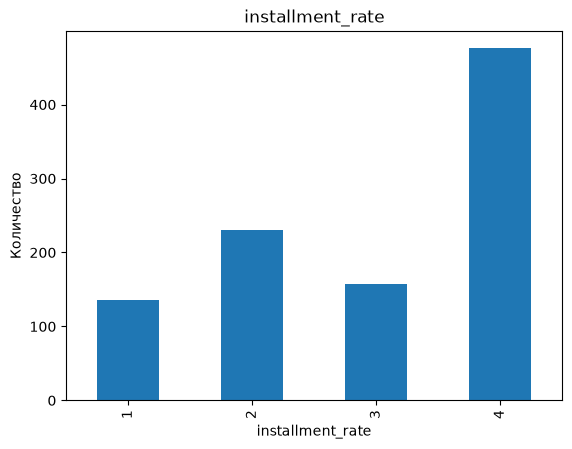

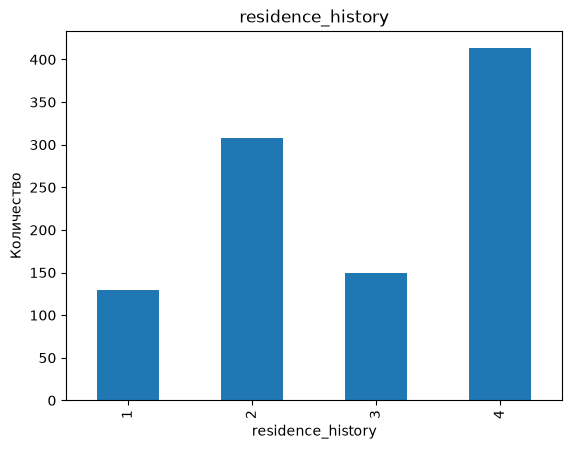

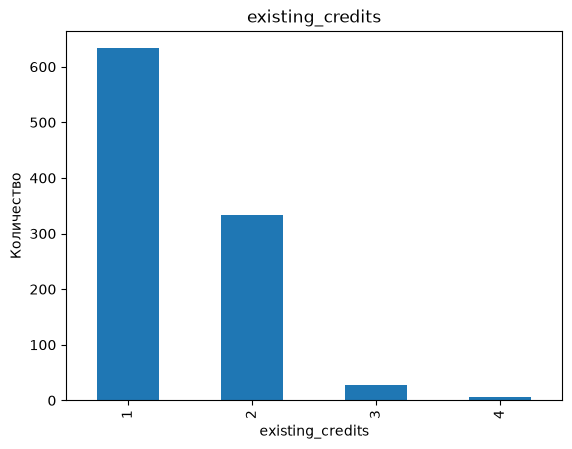

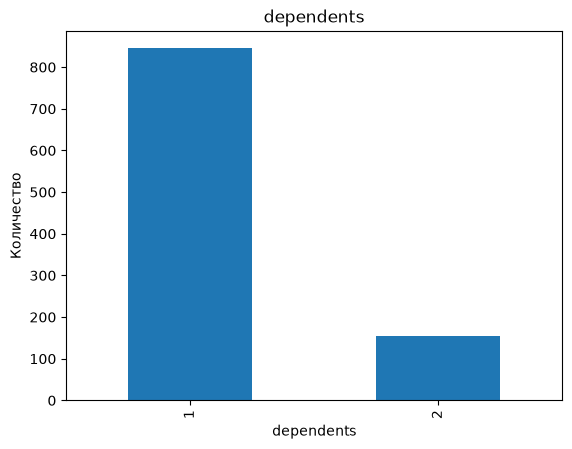

In [31]:
discrete_columns = [
    "installment_rate",
    "residence_history",
    "existing_credits",
    "dependents"
]

for column in discrete_columns:
    df[column].value_counts().sort_index().plot(kind="bar")
    plt.title(column)
    plt.xlabel(column)
    plt.ylabel("Количество")
    plt.show()

Для большинства дискретных признаков отдельные категории встречаются  чаще остальных

### Категориальные признаки

Рассмотрим распределения нескольких категориальных признаков.

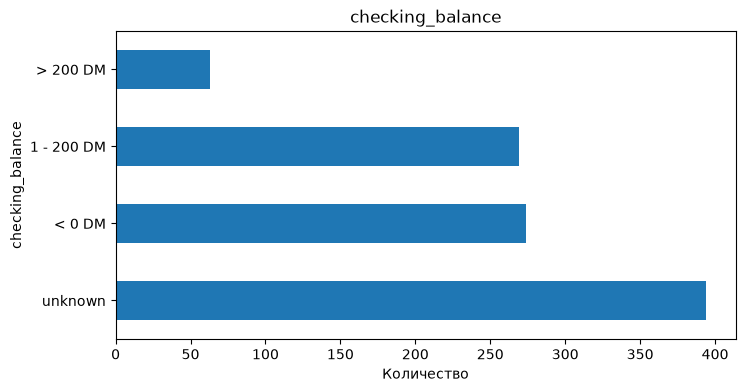

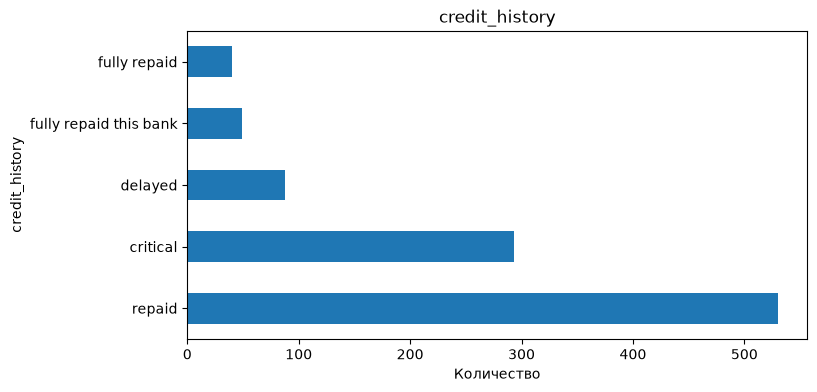

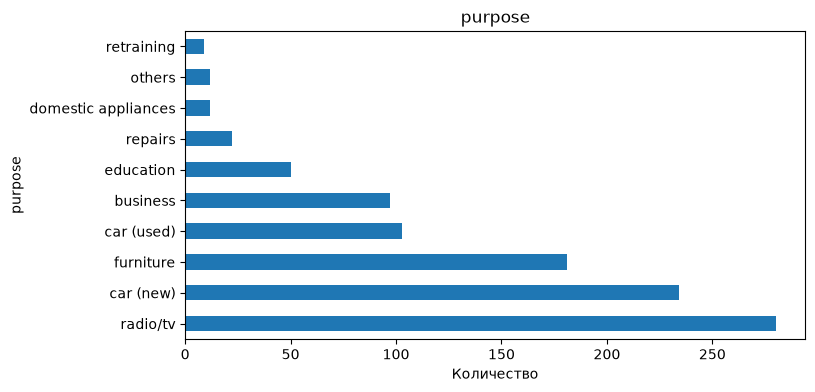

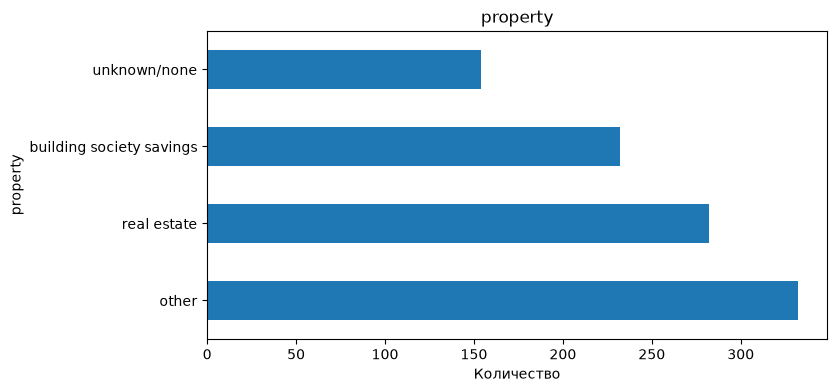

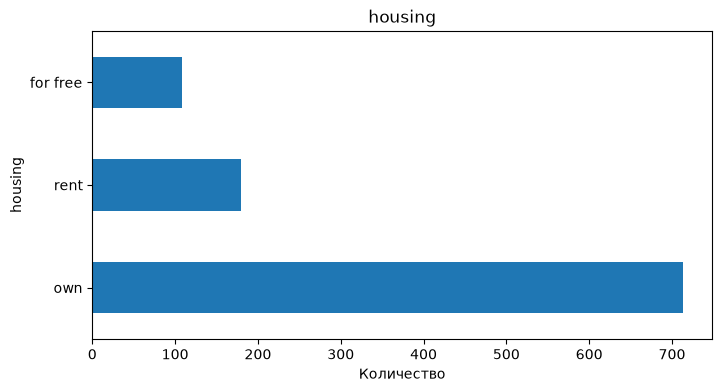

In [32]:
categorical_columns = [
    "checking_balance",
    "credit_history",
    "purpose",
    "property",
    "housing"
]

for column in categorical_columns:
    df[column].value_counts().plot(kind="barh", figsize=(8, 4))
    plt.title(column)
    plt.xlabel("Количество")
    plt.ylabel(column)
    plt.show()

### Совместное распределение числовых признаков

Построим график попарных зависимостей между суммой кредита, сроком кредита и возрастом клиента

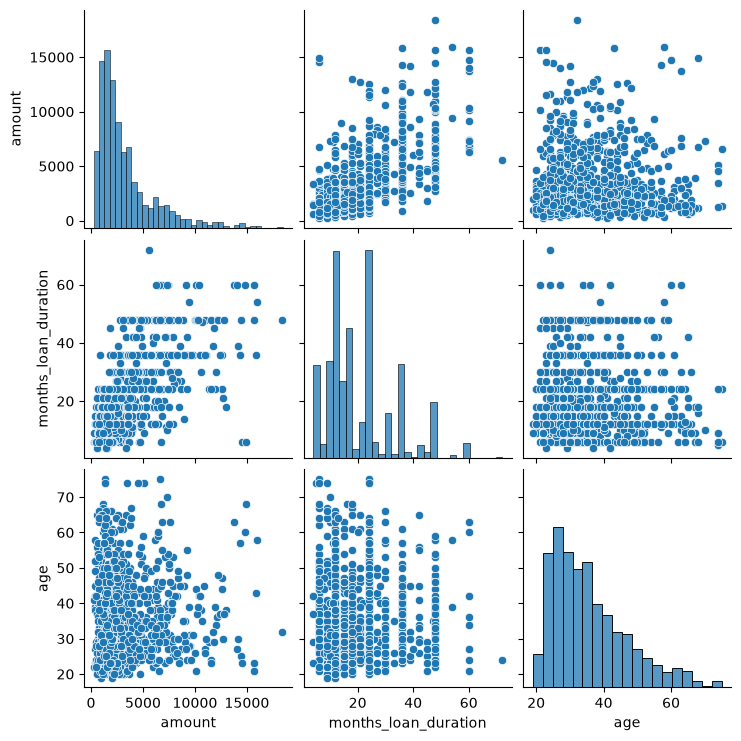

In [7]:
sns.pairplot(df[["amount", "months_loan_duration", "age"]])

Нет линейной зависимости между возрастом и суммой кредита. Между суммой кредита и сроком кредита есть положительная зависимость, так как кредиты на большую сумму чаще выдаются на более длительный срок.

Возраст также не имеет четкой зависимости от срока кредита.

### Связь срока и суммы кредита

Ранее заметили зависимость между сроком кредита и его суммой. Далее проверим связь, добавив линейную регрессию и коэффициент корреляции Пирсона

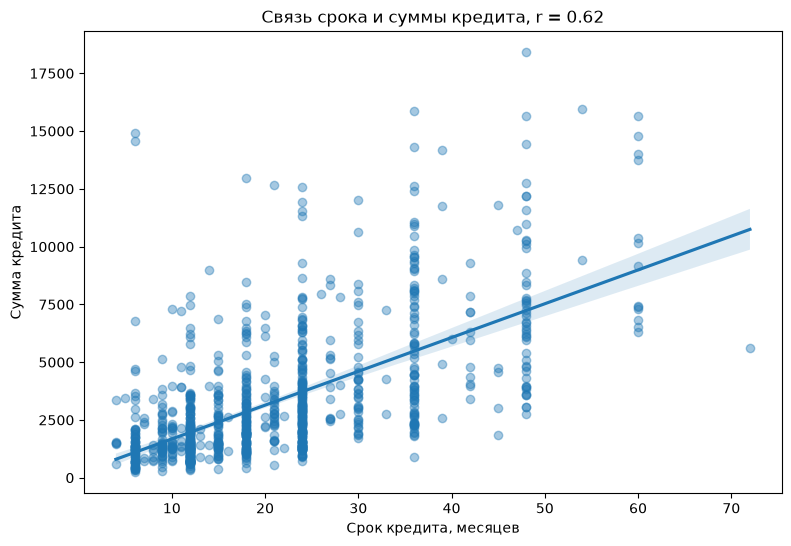

In [17]:
corr = df["months_loan_duration"].corr(df["amount"])
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="months_loan_duration",
    y="amount",
    scatter_kws={"alpha": 0.4}
)
plt.title(f"Связь срока и суммы кредита, r = {corr:.2f}")
plt.xlabel("Срок кредита, месяцев")
plt.ylabel("Сумма кредита")
plt.show()

Конечно, логично, что на большие кредиты дают больший срок. Корреляция Пирсона r = 0.62.

### Сумма кредита в зависимости от цели

Оценка распределения суммы кредита между целями кредитования.

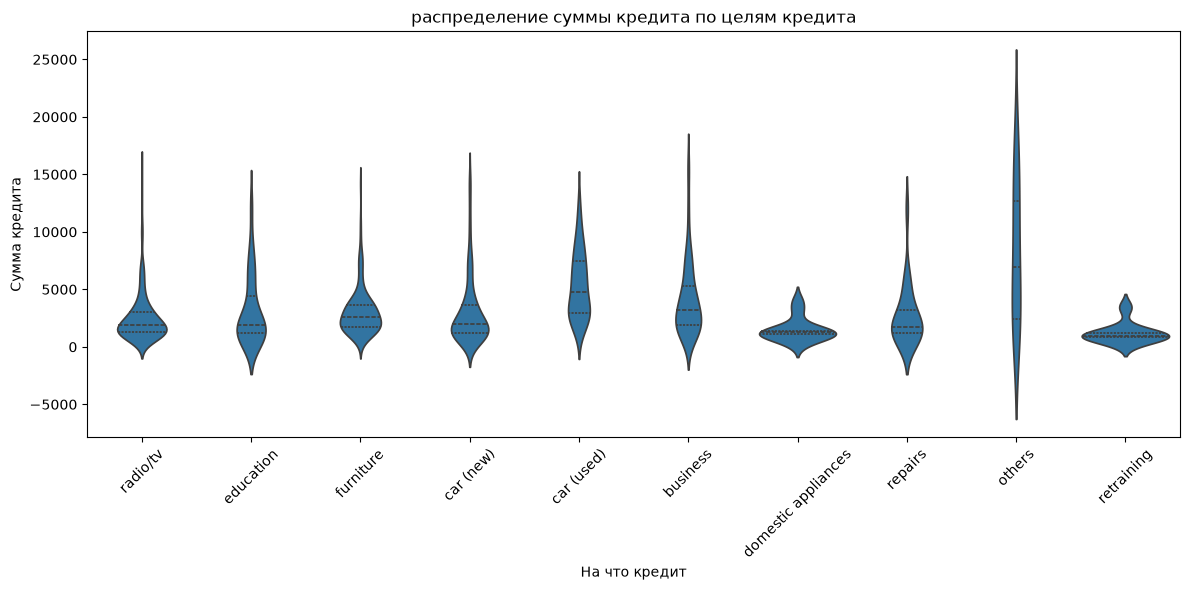

In [11]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x="purpose", y="amount",inner="quartile")
plt.xticks(rotation=45)
plt.title("распределение суммы кредита по целям кредита")
plt.xlabel("На что кредит")
plt.ylabel("Сумма кредита")
plt.tight_layout()
plt.show()

Самые большие кредиты были взяты на `others`, `business`, `car(used)`. Для `domestic appliances` и `retraining` кредиты в основном брали на небольшие суммы.

Также видно, что для некоторых целей распределение имеет длинный верхний хвост, то есть брали редкие кредиты с существенно большей суммой по сравнению с основной массой кредитов

### Сумма кредита в зависимости от типа жилья

Распределение суммы кредитов между клиентами с разным типом жилья. Swarmplot позволяет увидеть отдельные наблюдения

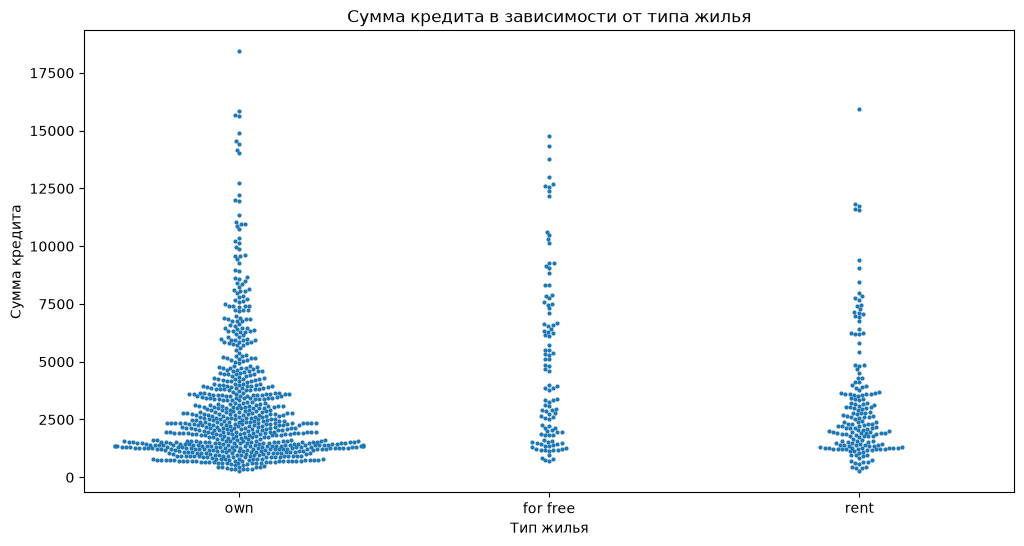

In [33]:
plt.figure(figsize=(12, 6))
sns.swarmplot(
    data=df,
    x="housing",
    y="amount",
    size=3
)
plt.title("Сумма кредита в зависимости от типа жилья")
plt.xlabel("Тип жилья")
plt.ylabel("Сумма кредита")
plt.show()

Для категории `own` представлено наибольшее число наблюдений, в основном это небольшие кредиты, но встречаются и очень большие. В категории `rent` число наблюдений меньше, меньше больших кредитов, но они все еще присутствуют. Для категории `for free` представлено меньшее число клиентов, в ней встречаются отдельные кредиты с крупными суммами.

## 6. Выбросы

Для оценки возможных выбросов рассмотрим boxplot основных числовых признаков.

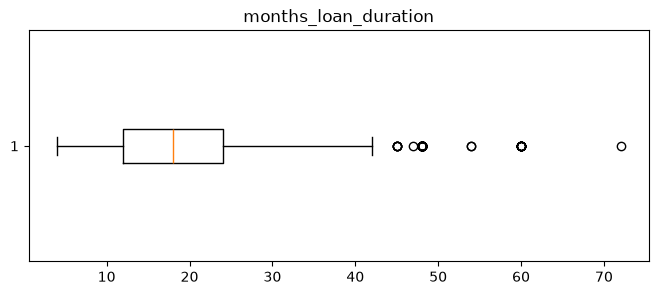

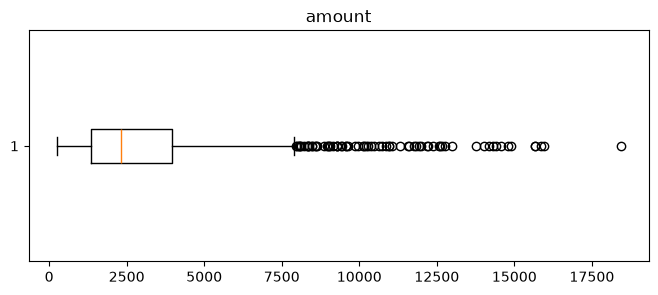

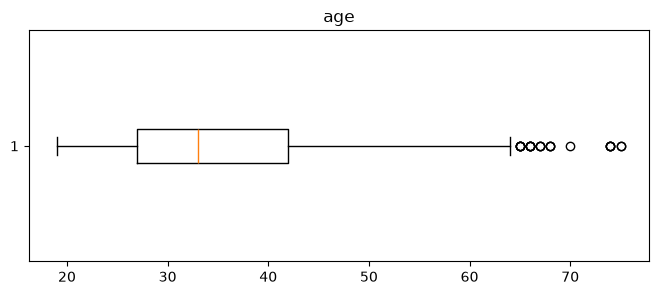

In [34]:
for column in ["months_loan_duration", "amount", "age"]:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[column], orientation='horizontal')
    plt.title(column)
    plt.show()

Наиболее заметные выбросы наблюдаются в признаке `amount`. Также отдельные крайние значения присутствуют в возрасте клиентов и сроке кредита.

### Оценка выбросов методом IQR

Посчитаем количество потенциальных выбросов для суммы кредита.

In [35]:
q1 = df["amount"].quantile(0.25)
q3 = df["amount"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

amount_outliers = df[
    (df["amount"] < lower)
    | (df["amount"] > upper)
]

print(f'По правилу IQR потенциальными выбросами являются {len(amount_outliers)} наблюдений, что составляет {round(len(amount_outliers) / len(df) * 100, 4)}% наблюдений')

По правилу IQR потенциальными выбросами являются 72 наблюдений, что составляет 7.2% наблюдений


## 7. Корреляции

Рассмотрим линейные связи между основными числовыми признаками.

<Axes: >

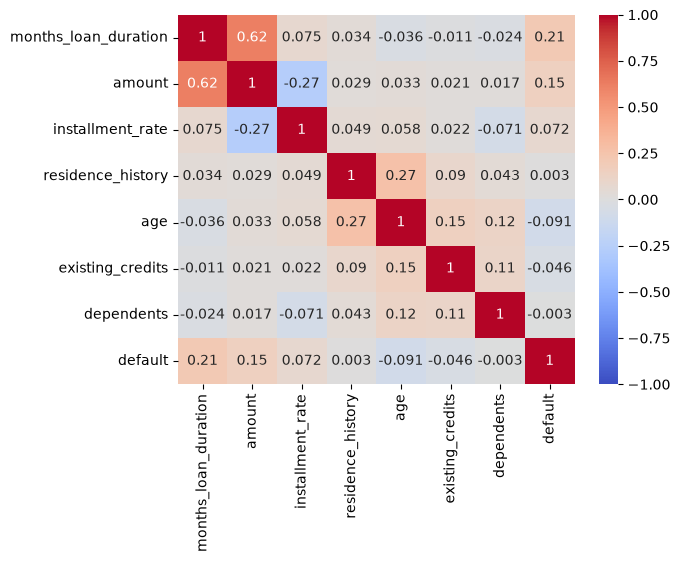

In [36]:
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)

## 8. Выводы

В ходе EDA были получены следующие результаты:

- датасет содержит 1000 наблюдений, 20 признаков и целевую переменную `default`
- стандартные пропущенные значения `NaN` отсутствуют
- в категориальных признаках присутствуют специальные значения `none` и `unknown`, которые требуют обработки
- распределение суммы кредита `amount` имеет сдвиг вправо и содержит потенциальные выбросы
- крайние значения также присутствуют для возраста и срока кредита
- часть числовых признаков являются дискретными или порядковыми
- категориальные признаки распределены неравномерно
- дальше необходимо решить, как обрабатывать значения `none` и `unknown`, а также определить, требуется ли обработка потенциальных выбросов
- целевая переменная (таргет) отдельно не рассматривалась в данном EDA анализе